# Notebook 03 - Linear Regression 2.2: predicting the goals a team scores in a match
**Sydney Group 19 - Assessment 3 (Objective 2)**

**Analytic question:** *Using only pre-match information, how many goals will a given team score in a
FIFA World Cup 2026 match, and does a count-aware model (Poisson) beat ordinary linear regression?*

Two methodological traps specific to this 208-row dataset are handled explicitly:
1. **Rows are paired.** Both teams of a match appear as two rows. Ordinary CV could put one half of a
   match in training and the other half in testing; ordinary SEs treat the halves as independent.
   We therefore use **match-grouped CV** and **cluster-robust standard errors**.
2. **The target is a non-negative count.** Linear regression can predict negative goals and assumes
   constant variance, whereas goal counts are roughly Poisson (variance close to the mean). We benchmark a
   **Poisson GLM** against the linear family.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import (LinearRegression, RidgeCV, LassoCV, ElasticNetCV,
                                  HuberRegressor, PoissonRegressor)
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_poisson_deviance
from wc_utils import (OLSInference, vif, cross_validate_models, summarise_cv,
                      corrected_paired_ttest, repeated_group_folds)

os.makedirs("../figures", exist_ok=True); os.makedirs("../results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
C = {"main": "#1f4e79", "accent": "#d1495b", "grey": "#8c8c8c", "green": "#2a9d8f", "gold": "#e9a03b"}

df = pd.read_csv("../data/processed/lr22_team_match_level.csv")
FEAT = ["strength_gap", "host_home", "rest_days", "home_dist_1000km",
        "gf_form", "opp_ga_form", "altitude_km", "knockout"]
TARGET = "goals"
X, y, groups = df[FEAT], df[TARGET], df["match_id"]
print(df.shape, "| explanatory variables:", len(FEAT), "| matches:", groups.nunique())

(208, 14) | explanatory variables: 8 | matches: 104


## 1. Exploratory data analysis - is the target Poisson-like?

In [2]:
mean_, var_ = y.mean(), y.var()
print(f"Goals per team-match: mean = {mean_:.3f}, variance = {var_:.3f}, dispersion ratio = {var_ / mean_:.2f}")
# Poisson goodness of fit on the raw counts (bins 0..4, 5+)
obs = np.bincount(np.minimum(y, 5), minlength=6)
exp_ = len(y) * np.append(stats.poisson.pmf(range(5), mean_), stats.poisson.sf(4, mean_))
chi2, p_gof = stats.chisquare(obs, exp_, ddof=1)
print(f"Chi-square GOF vs Poisson(mean): chi2 = {chi2:.2f}, p = {p_gof:.3f}")
corr = df[FEAT + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
corr.round(3)

Goals per team-match: mean = 1.481, variance = 1.942, dispersion ratio = 1.31
Chi-square GOF vs Poisson(mean): chi2 = 9.57, p = 0.048


strength_gap        0.484
opp_ga_form         0.203
host_home           0.139
home_dist_1000km   -0.120
rest_days          -0.099
gf_form             0.097
altitude_km        -0.035
knockout           -0.013
Name: goals, dtype: float64

## 2. Multicollinearity

In [3]:
v = vif(X).round(2); v

strength_gap        1.20
host_home           1.50
rest_days           1.14
home_dist_1000km    1.40
gf_form             1.34
opp_ga_form         1.27
altitude_km         1.11
knockout            1.30
Name: VIF, dtype: float64

## 3. Full-sample OLS with ordinary vs **cluster-robust** (by match) standard errors

In [4]:
ols = OLSInference().fit(X, y)
naive = ols.summary()
robust = ols.cluster_robust(groups)
comp = naive[["coef", "std_err", "p_value"]].join(robust[["cluster_se", "p_value", "ci_low", "ci_high"]],
                                                   rsuffix="_cluster").round(4)
comp

n = 208, predictors = 8
R2 = 0.275   adj R2 = 0.246   F = 9.43 (p = 5.02e-11)   AIC = 678.4   BIC = 708.5


,coef,std_err,p_value,cluster_se,p_value_cluster,ci_low,ci_high
const,2.3891,0.7002,0.0008,0.7912,0.0032,0.8201,3.9582
strength_gap,0.3921,0.0566,0.0000,0.0538,0.0000,0.2855,0.4988
host_home,0.9620,0.4243,0.0245,0.4803,0.0478,0.0094,1.9146
rest_days,-0.2245,0.1063,0.0360,0.1219,0.0683,-0.4662,0.0172
home_dist_1000km,0.0096,0.0327,0.7691,0.0295,0.7450,-0.0488,0.0680
gf_form,-0.1029,0.1575,0.5142,0.1472,0.4859,-0.3948,0.1890
opp_ga_form,0.2531,0.1608,0.1171,0.1760,0.1534,-0.0959,0.6022
altitude_km,-0.1553,0.1628,0.3411,0.1457,0.2889,-0.4443,0.1337
knockout,0.0157,0.2076,0.9397,0.1980,0.9368,-0.3769,0.4084


In [5]:
std_coef = robust.loc[FEAT, ["coef", "ci_low", "ci_high"]].mul(X.std(), axis=0).round(3)
std_coef["p_value"] = robust.loc[FEAT, "p_value"].round(4)
print("Negative fitted values from OLS:", int((ols.fitted < 0).sum()), "of", len(y))
std_coef.sort_values("coef", key=abs, ascending=False)

Negative fitted values from OLS: 4 of 208


,coef,ci_low,ci_high,p_value
strength_gap,0.638,0.464,0.811,0.0000
host_home,0.233,0.002,0.465,0.0478
rest_days,-0.190,-0.394,0.015,0.0683
opp_ga_form,0.149,-0.056,0.355,0.1534
altitude_km,-0.085,-0.242,0.073,0.2889
gf_form,-0.064,-0.244,0.117,0.4859
home_dist_1000km,0.029,-0.149,0.207,0.7450
knockout,0.007,-0.174,0.189,0.9368


## 4. Poisson GLM (log link) - interpretation as rate ratios
A coefficient b on a standardised predictor means: +1 SD multiplies expected goals by exp(b).

In [6]:
pois_full = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-6, max_iter=3000)).fit(X, y)
rr = pd.Series(np.exp(pois_full[-1].coef_), index=FEAT, name="rate ratio per +1 SD").round(3)
print("Intercept (expected goals for an average team):", round(np.exp(pois_full[-1].intercept_), 3))
rr.sort_values()

Intercept (expected goals for an average team): 1.3


rest_days           0.866
altitude_km         0.943
gf_form             0.952
knockout            1.001
home_dist_1000km    1.038
opp_ga_form         1.106
host_home           1.179
strength_gap        1.579
Name: rate ratio per +1 SD, dtype: float64

## 5. Competing algorithms - match-grouped repeated 10-fold CV (100 folds)
Metrics: RMSE, MAE and **mean Poisson deviance** (the proper scoring rule for counts; linear
predictions are clipped at 0.01 only for this deviance metric).

In [7]:
class FirstColumn(BaseEstimator, RegressorMixin):
    """One-variable benchmark using strength_gap only."""
    def __init__(self, model): self.model = model
    def fit(self, X, y): self.m_ = clone(self.model).fit(X[:, [0]], y); return self
    def predict(self, X): return self.m_.predict(X[:, [0]])

alphas = np.logspace(-3, 2, 60)
models = {
    "Baseline (mean)": DummyRegressor(),
    "OLS strength only": FirstColumn(make_pipeline(StandardScaler(), LinearRegression())),
    "OLS (8 vars)": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=5, max_iter=50000, random_state=0)),
    "Elastic Net": make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.2, .5, .8], alphas=alphas, cv=5,
                                                                max_iter=50000, random_state=0)),
    "Huber (robust)": make_pipeline(StandardScaler(), HuberRegressor(max_iter=2000)),
    "Poisson GLM": make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-6, max_iter=3000)),
}
dev = lambda yt, yp: mean_poisson_deviance(yt, np.clip(yp, 0.01, None))
neg = lambda yt, yp: float(np.mean(yp < 0))
scores = cross_validate_models(models, X.values, y.values, groups=groups, n_splits=10, n_repeats=10,
                               seed=42, extra_metrics={"Poisson_dev": dev, "Share_negative": neg})
cv_table = summarise_cv(scores, metrics=("RMSE", "MAE", "R2", "Poisson_dev", "Share_negative"))
cv_table[["RMSE", "RMSE_sd", "MAE", "R2", "Poisson_dev", "Share_negative"]]

,RMSE,RMSE_sd,MAE,R2,Poisson_dev,Share_negative
model,,,,,,
OLS strength only,1.199,0.269,0.908,0.187,1.232,0.015
Elastic Net,1.208,0.267,0.918,0.172,1.202,0.011
Lasso,1.209,0.268,0.918,0.171,1.203,0.012
Ridge,1.212,0.264,0.926,0.164,1.201,0.012
Huber (robust),1.213,0.264,0.909,0.163,1.243,0.027
OLS (8 vars),1.217,0.262,0.927,0.152,1.197,0.020
Poisson GLM,1.224,0.277,0.929,0.138,1.136,0.000
Baseline (mean),1.368,0.273,1.115,-0.045,1.418,0.000


In [8]:
k = scores.groupby(["model", "repeat"]).cumcount()
piv = scores.assign(k=k).pivot_table(index=["repeat", "k"], columns="model", values="RMSE")
pdev = scores.assign(k=k).pivot_table(index=["repeat", "k"], columns="model", values="Poisson_dev")
rows = []
for a_, b_ in [("OLS (8 vars)", "Baseline (mean)"), ("Poisson GLM", "Baseline (mean)"),
               ("Poisson GLM", "OLS (8 vars)"), ("Lasso", "OLS (8 vars)"), ("Ridge", "OLS (8 vars)"),
               ("OLS (8 vars)", "OLS strength only"), ("Poisson GLM", "OLS strength only")]:
    d, t, p = corrected_paired_ttest(piv[a_], piv[b_], n_train=187, n_test=21)
    d2, t2, p2 = corrected_paired_ttest(pdev[a_], pdev[b_], n_train=187, n_test=21)
    rows.append({"model A": a_, "model B": b_, "dRMSE": round(d, 4), "p (RMSE)": round(p, 4),
                 "dDeviance": round(d2, 4), "p (deviance)": round(p2, 4)})
ttests = pd.DataFrame(rows); ttests

,model A,model B,dRMSE,p (RMSE),dDeviance,p (deviance)
0,OLS (8 vars),Baseline (mean),-0.1515,0.0024,-0.2210,0.0745
1,Poisson GLM,Baseline (mean),-0.1441,0.0128,-0.2818,0.0009
2,Poisson GLM,OLS (8 vars),0.0073,0.7731,-0.0609,0.4145
3,Lasso,OLS (8 vars),-0.0075,0.6104,0.0058,0.8028
4,Ridge,OLS (8 vars),-0.0041,0.6493,0.0036,0.8299
5,OLS (8 vars),OLS strength only,0.0174,0.4922,-0.0347,0.4984
6,Poisson GLM,OLS strength only,0.0247,0.4985,-0.0955,0.3462


## 6. Out-of-time validation: train on group stage (144 rows), test on knockouts (64 rows)

In [9]:
grp = df.knockout == 0
oot = []
for name, mdl in models.items():
    if name == "Baseline (mean)" or True:
        Xtr = X[grp].values.copy(); Xte = X[~grp].values.copy()
        if "knockout" in FEAT:  # knockout is constant (0) in training -> drop it for this test only
            j = FEAT.index("knockout"); Xtr[:, j] = 0; Xte[:, j] = 0
        mm = clone(mdl).fit(Xtr, y[grp].values); p_ = mm.predict(Xte)
        oot.append({"model": name, "RMSE": np.sqrt(mean_squared_error(y[~grp], p_)),
                    "MAE": mean_absolute_error(y[~grp], p_), "Poisson_dev": dev(y[~grp].values, p_)})
oot = pd.DataFrame(oot).set_index("model").round(3).sort_values("RMSE"); oot

,RMSE,MAE,Poisson_dev
model,,,
Ridge,1.090,0.794,1.151
Elastic Net,1.090,0.788,1.174
Lasso,1.093,0.787,1.191
Huber (robust),1.104,0.787,1.174
Poisson GLM,1.114,0.828,1.000
OLS (8 vars),1.115,0.799,1.192
OLS strength only,1.126,0.818,1.449
Baseline (mean),1.212,0.984,1.158


## 7. Linking the two tasks: can the goals model reproduce the goal difference?
For every match, predicted goal difference = predicted goals(A) - predicted goals(B) from the 2.2 model.
We compare this **indirect** forecast with the **direct** 2.1 models on identical match-level folds.

In [10]:
d21 = pd.read_csv("../data/processed/lr21_match_level.csv")
F21 = ["strength_diff", "form_gd_diff", "host_diff", "rest_diff", "travel_diff_1000km",
       "home_dist_diff_1000km", "wc_exp_diff", "elite_confed_diff"]
side = df.merge(d21[["match_id", "team_a"]], on="match_id")
side["is_a"] = side.team == side.team_a
ids = d21.match_id.values
res_link = []
for r, tr, te in repeated_group_folds(ids, 10, 10, seed=42):
    tr_ids, te_ids = set(ids[tr]), set(ids[te])
    out = {"repeat": r}
    # direct 2.1 models
    for nm in ["Lasso", "OLS strength only"]:
        mdl = (make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=5, max_iter=50000, random_state=0))
               if nm == "Lasso" else FirstColumn(make_pipeline(StandardScaler(), LinearRegression())))
        mdl.fit(d21.loc[tr, F21].values, d21.loc[tr, "goal_diff"].values)
        out["2.1 " + nm] = np.sqrt(mean_squared_error(d21.loc[te, "goal_diff"], mdl.predict(d21.loc[te, F21].values)))
    # indirect via 2.2
    trm, tem = side.match_id.isin(tr_ids), side.match_id.isin(te_ids)
    for nm in ["Poisson GLM", "OLS (8 vars)"]:
        mdl = clone(models[nm]).fit(side.loc[trm, FEAT].values, side.loc[trm, TARGET].values)
        t_ = side[tem].copy(); t_["pred"] = mdl.predict(t_[FEAT].values)
        t_["sgn"] = np.where(t_.is_a, 1, -1)
        gd_hat = (t_.pred * t_.sgn).groupby(t_.match_id).sum()
        gd_true = (t_[TARGET] * t_.sgn).groupby(t_.match_id).sum()
        out["2.2 " + nm + " -> GD"] = np.sqrt(mean_squared_error(gd_true, gd_hat))
    res_link.append(out)
link = pd.DataFrame(res_link).drop(columns="repeat").agg(["mean", "std"]).T.round(3).sort_values("mean")
link

,mean,std
2.1 OLS strength only,1.540,0.416
2.2 OLS (8 vars) -> GD,1.547,0.407
2.2 Poisson GLM -> GD,1.570,0.395
2.1 Lasso,1.586,0.419


## 8. Figures for the report

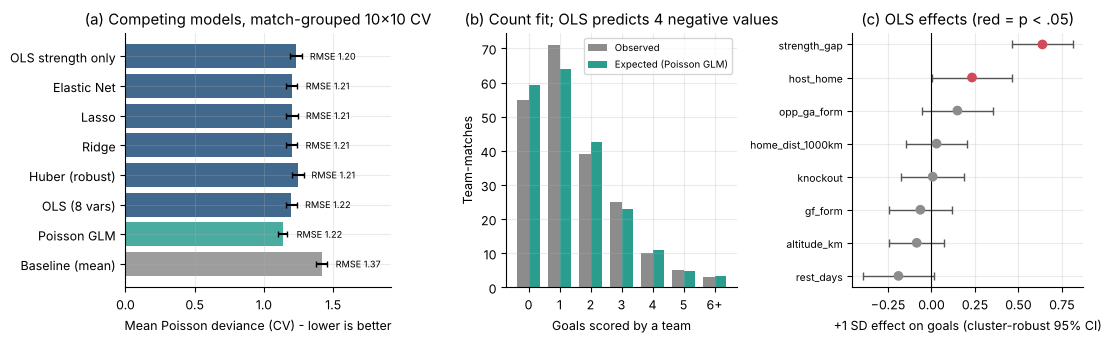

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1.15, 1, 1]})
order = cv_table.sort_values("RMSE", ascending=False).index
cl = [C["grey"] if "Baseline" in m_ else C["green"] if m_ == "Poisson GLM" else C["main"] for m_ in order]
ax[0].barh(order, cv_table.loc[order, "Poisson_dev"], color=cl, alpha=.85,
           xerr=cv_table.loc[order, "Poisson_dev_sd"] / 10, capsize=2)
for i, m_ in enumerate(order):
    ax[0].text(cv_table.loc[m_, "Poisson_dev"] + .1, i, f"RMSE {cv_table.loc[m_, 'RMSE']:.2f}", va="center", fontsize=6.6)
ax[0].set_xlim(0, cv_table.Poisson_dev.max() * 1.35)
ax[0].set_xlabel("Mean Poisson deviance (CV) - lower is better")
ax[0].set_title("(a) Competing models, match-grouped 10x10 CV")
# observed vs expected count distribution
ols_full = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
mu_p = pois_full.predict(X); mu_o = ols_full.predict(X)
ks = np.arange(0, 7)
obs_k = np.array([(y == k_).sum() if k_ < 6 else (y >= 6).sum() for k_ in ks])
exp_p = np.array([stats.poisson.pmf(k_, mu_p).sum() if k_ < 6 else stats.poisson.sf(5, mu_p).sum() for k_ in ks])
w = .38
ax[1].bar(ks - w / 2, obs_k, w, color=C["grey"], label="Observed")
ax[1].bar(ks + w / 2, exp_p, w, color=C["green"], label="Expected (Poisson GLM)")
ax[1].set_xticks(ks); ax[1].set_xticklabels([str(k_) for k_ in ks[:-1]] + ["6+"])
ax[1].set_xlabel("Goals scored by a team"); ax[1].set_ylabel("Team-matches"); ax[1].legend(fontsize=7)
ax[1].set_title(f"(b) Count fit; OLS predicts {int((mu_o < 0).sum())} negative values")
sc = std_coef.sort_values("coef")
cc = [C["accent"] if p_ < .05 else C["grey"] for p_ in sc.p_value]
ax[2].errorbar(sc.coef, range(8), xerr=[sc.coef - sc.ci_low, sc.ci_high - sc.coef], fmt="none", ecolor="#555", capsize=3, lw=1)
ax[2].scatter(sc.coef, range(8), c=cc, s=36, zorder=3); ax[2].axvline(0, c="black", lw=.8)
ax[2].set_yticks(range(8)); ax[2].set_yticklabels(sc.index, fontsize=7.5)
ax[2].set_xlabel("+1 SD effect on goals (cluster-robust 95% CI)")
ax[2].set_title("(c) OLS effects (red = p < .05)")
plt.tight_layout(); plt.savefig("../figures/fig4_lr22_models.png", dpi=200, bbox_inches="tight"); plt.show()

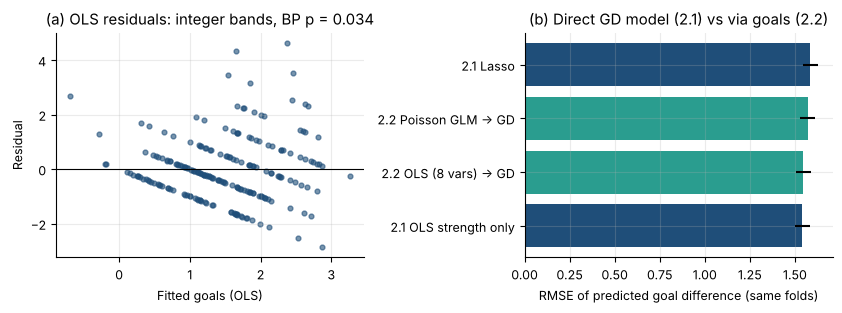

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.2))
ax[0].scatter(ols.fitted, ols.resid, s=12, alpha=.6, c=C["main"]); ax[0].axhline(0, c="black", lw=.8)
ax[0].set_xlabel("Fitted goals (OLS)"); ax[0].set_ylabel("Residual"); ax[0].set_title(f"(a) OLS residuals: integer bands, BP p = {ols.diagnostics()['BP p-value']:.3f}")
lk = link["mean"].sort_values()
ax[1].barh(lk.index, lk.values, xerr=link.loc[lk.index, "std"] / 10, color=[C["green"] if "2.2" in i else C["main"] for i in lk.index])
ax[1].set_xlabel("RMSE of predicted goal difference (same folds)")
ax[1].set_title("(b) Direct GD model (2.1) vs via goals (2.2)")
plt.tight_layout(); plt.savefig("../figures/fig5_lr22_diagnostics_link.png", dpi=200, bbox_inches="tight"); plt.show()

## 9. Residual diagnostics

In [13]:
diag = ols.diagnostics(); diag.round(4)

Breusch-Pagan LM    16.6204
BP p-value           0.0343
Shapiro-Wilk W       0.9548
SW p-value           0.0000
Durbin-Watson        1.9312
Skew                 0.9021
Kurtosis             1.6655
dtype: float64

## 10. Save results

In [14]:
res = {"n": int(len(df)), "mean": mean_, "var": var_, "gof_chi2": chi2, "gof_p": p_gof,
       "ols_r2": ols.r2, "ols_adj_r2": ols.adj_r2, "ols_f": ols.f_stat, "ols_f_p": ols.f_p,
       "neg_fitted": int((ols.fitted < 0).sum()), "coef_compare": comp.reset_index().to_dict("records"),
       "std_coef": std_coef.reset_index().to_dict("records"), "rate_ratios": rr.to_dict(),
       "pois_intercept": float(np.exp(pois_full[-1].intercept_)), "vif": v.to_dict(),
       "cv_table": cv_table.reset_index().to_dict("records"), "ttests": ttests.to_dict("records"),
       "oot": oot.reset_index().to_dict("records"), "link": link.reset_index().to_dict("records"),
       "diagnostics": diag.to_dict(), "corr_with_target": corr.to_dict()}
json.dump(res, open("../results/lr22_results.json", "w"), indent=1, default=float)
print("saved")

saved
